# How much do the head-motion conventions change FD?

fMRIPrep reports MCFLIRT's and 3dvolreg's motion parameters on RAS+ axes, but each keeps its tool's rotation center and Euler order.
So identical motion gives different parameters, and possibly different FD and censoring.
This notebook measures the gap, to help choose between **preserving tool values** and **consistent determinations** (identical motion gives identical FD, whichever `--hmc-method` tool ran).

## Summary

In [1]:
from IPython.display import Markdown, display

summary = display(Markdown('_Run the notebook to fill in the summary._'), display_id='summary')

**Threshold bounds.** In this simulated sample (10,000 frame pairs, pose SD 1.5°, on the reference grid, where the center distance is d = 7.1 mm), the relative FD difference between the conventions does not depend on FD, so the bounds scale with τ.

A frame one convention keeps (FD ≤ τ) measures at most this under the other:

| τ (mm) | 99% of frames | sample maximum | analytic, translation term only |
| --- | --- | --- | --- |
| 0.2 | 0.219 (+9.7%) | 0.233 (+16.5%) | 0.249 (+24.5%) |
| 0.5 | 0.548 (+9.7%) | 0.583 (+16.5%) | 0.622 (+24.5%) |
| 1 | 1.097 (+9.7%) | 1.165 (+16.5%) | 1.245 (+24.5%) |

A frame one convention censors (FD > τ) measures at least this under the other:

| τ (mm) | 99% of frames | sample maximum | analytic, translation term only |
| --- | --- | --- | --- |
| 0.2 | 0.182 (-8.8%) | 0.172 (-14.2%) | 0.151 (-24.5%) |
| 0.5 | 0.456 (-8.8%) | 0.429 (-14.2%) | 0.378 (-24.5%) |
| 1 | 0.912 (-8.8%) | 0.858 (-14.2%) | 0.755 (-24.5%) |

- **The maximum is not a guarantee.** It grows with sample size (from +13.7% with 1,000 pairs to +16.5% with 10,000); the 99th percentile is stable (+9.66% to +9.68%). The analytic bound covers only FD's translation term.
- **Disagreement near τ** falls steeply with distance from it: 44% within 1%, 38% at 1%–2%, 25% at 2%–4%, 14% at 4%–6%, 5% at 6%–8%, 1% at 8%–10% of τ (averaged over ±10%: 16%–18%). These rates come from a synthetic distribution of FD and motion directions, not from real data.
- **Center distance.** The bounds widen with d, which depends on the field of view and where the brain sits in it. From d = 3.3 to 39.8 mm (sample, 99th percentile):
  - τ = 0.2 mm: kept frames measure up to 0.210 mm at d = 3.3 mm and 0.280 mm at 39.8 mm; censored frames as low as 0.191 and 0.143 mm.
  - τ = 0.5 mm: kept frames measure up to 0.524 mm at d = 3.3 mm and 0.700 mm at 39.8 mm; censored frames as low as 0.477 and 0.357 mm.
  - τ = 1 mm: kept frames measure up to 1.049 mm at d = 3.3 mm and 1.401 mm at 39.8 mm; censored frames as low as 0.954 and 0.714 mm.
  - Band-averaged disagreement rises from 7%–9% to 38%–43%.
- **3dvolreg series:** 3 of 199 frames are censored by one convention only, at any threshold. Only 14 frames lie within ±10% of a threshold, none closer than 0.3%; the disagreement curve predicts about 2.0 among them.
- **Expectation 1** (Euler order is negligible): borne out for the parameters (at most 0.012°); **not borne out** for FD. The rotation term changes FD by up to 1.5% on the series (pose SD 0.30°) and 7.2% in the sample (1.50°), against the 1% criterion.
- **Expectation 2** (√3·d/50 bounds the change): borne out for the translation term at every distance. The total exceeds it in the sample (pose SD 1.5°) for the grid padded 20 mm posterior (d = 3.3 mm), because of Euler order; on the series it stays under.
- **Expectation 3** (regression leaves little), on the series: for 6 parameters, borne out (residual SD at most 0.0043 at every distance); for 24, borne out up to d = 11.6 mm (0.096), **not borne out** from d = 13.1 mm, reaching 0.23 at d = 39.8 mm.

## Setup

In [2]:
import logging
from pathlib import Path
from tempfile import TemporaryDirectory

import fmriprep
import matplotlib.pyplot as plt
import nibabel as nb
import nitransforms as nt
import niworkflows
import numpy as np
import pandas as pd
from fmriprep.interfaces.nitransforms import VolregToITK
from fmriprep.utils.transforms import volreg_to_ras
from nipype.pipeline.engine import Node

from hmc_impact.analysis import (
    COLUMNS,
    ROTATIONS,
    censor_counts,
    disagreement,
    disagreement_curve,
    expand24,
    regress_out,
    relative_parts,
    relative_quantiles,
    relative_spread,
    threshold_bounds,
)
from hmc_impact.conventions import (
    center_distance,
    framewise_displacement,
    motion_params,
    pad_image,
    rms_displacement,
    to_volreg_1d,
)
from hmc_impact.motion import THRESHOLDS, near_threshold_sides, sample_fd_targets, simulate_pairs

# niworkflows selects matplotlib's Agg backend on import; restore inline figures
%matplotlib inline
logging.getLogger('nipype.workflow').setLevel(logging.WARNING)

CONVENTIONS = ('afni', 'fsl')
LABEL = {'afni': 'AFNI', 'fsl': 'MCFLIRT'}
COLOR = {'afni': 'tab:blue', 'fsl': 'tab:orange'}

_tmp = TemporaryDirectory()
WORK = Path(_tmp.name)

display(
    Markdown(
        f'fMRIPrep `{fmriprep.__version__}`, niworkflows `{niworkflows.__version__}`. '
        f'FD thresholds: {", ".join(f"{t:g}" for t in THRESHOLDS)} mm.'
    )
)

fMRIPrep `26.0.0.dev1126+g18076e21e`, niworkflows `1.16.0.dev22+g0bdee79e1`. FD thresholds: 0.2, 0.5, 1 mm.

In [3]:
def convert(xfms, img, tag):
    """AFNI and MCFLIRT parameters (mm, rad) and FD for RAS affines expressed on ``img``."""
    params = {c: motion_params(xfms, img, c, WORK / f'{tag}_{c}') for c in CONVENTIONS}
    fd = {c: framewise_displacement(params[c], WORK / f'{tag}_{c}') for c in CONVENTIONS}
    return params, fd


def bounds_table(fd, band):
    """Per threshold: each convention's FD bounded by the other's decision, and disagreement."""
    rows = {}
    for tau in THRESHOLDS:
        row = {}
        for a, b in (('afni', 'fsl'), ('fsl', 'afni')):
            high, low = threshold_bounds(fd[a], fd[b], tau)
            p, n = disagreement(fd[a], fd[b], tau, band)
            row[f'max {LABEL[b]} | {LABEL[a]} ≤ τ'] = high
            row[f'min {LABEL[b]} | {LABEL[a]} > τ'] = low
            row[f'P(disagree) | {LABEL[a]} near τ'] = p
            row[f'n | {LABEL[a]} near τ'] = n
        rows[tau] = row
    return pd.DataFrame.from_dict(rows, orient='index').rename_axis('τ (mm)')


def regression_summary(params):
    """r2 range and worst relative residual SD, regressing each convention out of the other."""
    rows = {}
    for a, b in (('afni', 'fsl'), ('fsl', 'afni')):
        for model, expand in (('6', lambda p: p[COLUMNS]), ('24', expand24)):
            _, s = regress_out(expand(params[b]), expand(params[a]))
            rows[(f'{LABEL[b]} from {LABEL[a]}', model)] = {
                'min r2': s.r2.min(),
                'max r2': s.r2.max(),
                'max rel. resid. SD': s.rel_resid_sd.max(),
                'worst column': s.r2.idxmin(),
            }
    return pd.DataFrame.from_dict(rows, orient='index').rename_axis(['target', 'parameters'])


def difference_stats(params, fd, rows, q):
    """Relative FD difference over ``rows``: its FD terms, and ``relative_spread`` at ``q`` and 1."""
    parts = relative_parts(params['afni'], params['fsl'], fd['afni'], fd['fsl']).iloc[rows].abs()
    a, b = fd['afni'][rows], fd['fsl'][rows]
    (up, down), (up_max, down_max) = relative_spread(a, b, q), relative_spread(a, b, 1)
    return {
        'max |rel. ΔFD|': parts['total'].max(),
        'translation term': parts['translation'].max(),
        'rotation term': parts['rotation'].max(),
        'median': parts['total'].median(),
        'up, pct': up,
        'down, pct': down,
        'up, max': up_max,
        'down, max': down_max,
    }


def pose_sd(params):
    """Mean SD of the translations (mm) and of the rotations (degrees)."""
    return params[COLUMNS[:3]].std().mean(), np.rad2deg(params[ROTATIONS].std()).mean()


def pad_label(img, pad):
    """Where ``pad_image`` adds voxels, as anatomical directions in mm."""
    side = dict(zip('LRAPSI', ('right', 'left', 'posterior', 'anterior', 'inferior', 'superior')))
    zooms = img.header.get_zooms()
    parts = [
        f'{before * zoom:g} mm {side[code]}'
        for (before, _), zoom, code in zip(pad, zooms, nb.aff2axcodes(img.affine))
        if before
    ]
    return ', '.join(parts) or 'none'


def verdict(ok, bold=True):
    """'borne out' or 'not borne out', the latter in bold unless the caller already bolds it."""
    return 'borne out' if ok else ('**not borne out**' if bold else 'not borne out')


def percentile(q):
    """'99th percentile' for 0.99."""
    n = round(100 * q)
    suffix = 'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')
    return f'{n}{suffix} percentile'


def pct_range(values):
    lo, hi = f'{min(values):.0%}', f'{max(values):.0%}'
    return lo if lo == hi else f'{lo}–{hi}'


def to_display_units(params):
    """Copy of ``params`` with rotations in degrees."""
    out = params[COLUMNS].copy()
    out[ROTATIONS] = np.rad2deg(out[ROTATIONS])
    return out


def threshold_lines(ax, vertical=False):
    for tau in THRESHOLDS:
        ax.axhline(tau, color='0.6', lw=0.8, ls=':')
        if vertical:
            ax.axvline(tau, color='0.6', lw=0.8, ls=':')

## Conventions

The same rigid transform can be written as six parameters in more than one way:

- **AFNI** (`AFNIMotionParams`): rotations about the center of the de-obliqued grid, composed `Ry @ Rx @ Rz` in AFNI's axes.
- **MCFLIRT** (`FSLMotionParams`): translations of the reference's center of gravity, rotations composed `Rx @ Ry @ Rz` in FSL's axes.

FD adds the absolute frame-to-frame changes of all six, with rotations as arc length on a 50 mm sphere.
If the conventions' differences change FD by more than a threshold's margin, the same frame is kept under one and censored under the other.

**Expectations to test.** These are expectations, not findings; the sections below check them.

1. Euler order alone changes the rotations by about the product of two angles: negligible.
2. Moving the rotation center by `d` adds about `Δω × d` to each frame-to-frame translation.
   FD's rotation term is at least `50·|Δω|`, so the relative FD change should stay under about `√3·d/50`: 3.5% per mm of center distance in the worst case, less in typical frames.
3. That shift is linear in the rotations, so each parameter set should be nearly a linear combination of the other, and regressing one out of the other should leave little.

Each section that tests an expectation ends with a verdict. "Negligible" and "little" need numbers; these are the criteria the verdicts use:

In [4]:
NEGLIGIBLE_FD = 0.01  # Expectation 1: changes FD by less than this fraction
SMALL_RESIDUAL = 0.1  # Expectation 3: residual SD below this fraction of the column's SD

display(
    Markdown(
        f'- Expectation 1: Euler order changes the rotations by no more than the largest product '
        f'of two angles, and changes FD by less than {NEGLIGIBLE_FD:.0%}.\n'
        f"- Expectation 3: residual SD under {SMALL_RESIDUAL:.0%} of each column's SD."
    )
)

- Expectation 1: Euler order changes the rotations by no more than the largest product of two angles, and changes FD by less than 1%.
- Expectation 3: residual SD under 10% of each column's SD.

## The 3dvolreg series

`data/` holds one 3dvolreg (AFNI_26.3.09, `-cubic -zpad 1`) registration of a 200-volume synthetic series, made by `scripts/generate_volreg.py`.
`VolregToITK` turns its parameters into transforms and cross-checks them against the saved matrices.

In [5]:
DATA = Path('data').resolve()
boldref = nb.load(DATA / 'boldref.nii.gz')
volreg_1d = np.loadtxt(DATA / 'volreg.1D')

itk = (
    Node(
        VolregToITK(
            in_params=str(DATA / 'volreg.1D'),
            in_matrices=str(DATA / 'volreg.aff12.1D'),
            reference=str(DATA / 'boldref.nii.gz'),
        ),
        name='volreg_to_itk',
        base_dir=str(WORK),
    )
    .run()
    .outputs.out_file
)
series_xfms = nt.linear.load(itk).matrix
series_params, series_fd = convert(series_xfms, boldref, 'series')

roundtrip = np.abs(to_volreg_1d(series_params['afni']) - volreg_1d).max()
assert roundtrip < 1e-5, roundtrip
d_ref = center_distance(boldref)

display(
    Markdown(
        f'`AFNIMotionParams` reproduces `volreg.1D` to within {roundtrip:.1g} (degrees and mm), '
        'so the differences below come from the conventions, not the conversion. '
        f'The reference grid center and center of gravity are {d_ref:.1f} mm apart.'
    )
)

`AFNIMotionParams` reproduces `volreg.1D` to within 1e-06 (degrees and mm), so the differences below come from the conventions, not the conversion. The reference grid center and center of gravity are 7.1 mm apart.

The script required frames just below and just above each threshold (within 15%). The check, repeated on both FDs:

In [6]:
sides = pd.DataFrame(
    {
        (LABEL[c], side): {tau: hit[i] for tau, hit in near_threshold_sides(series_fd[c]).items()}
        for c in CONVENTIONS
        for i, side in enumerate(('below', 'above'))
    }
).rename_axis('τ (mm)')
assert sides['AFNI'].all(axis=None)
sides

AFNI       MCFLIRT      
       below above   below above
τ (mm)                          
0.2     True  True    True  True
0.5     True  True    True  True
1.0     True  True    True  True

## Parameters

How far apart are the two parameter sets over the series?

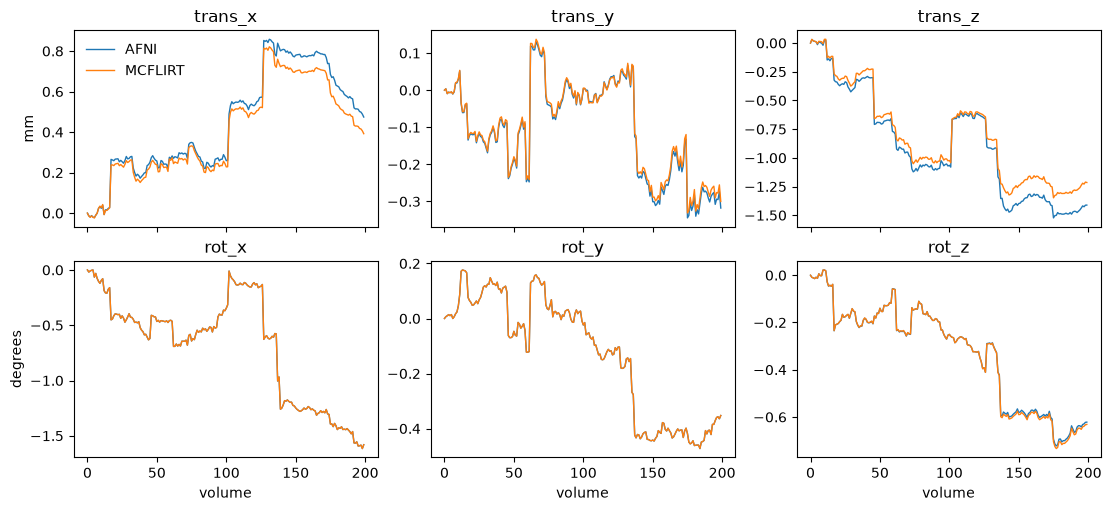

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, layout='constrained')
shown = {c: to_display_units(series_params[c]) for c in CONVENTIONS}
for ax, col in zip(axes.flat, COLUMNS):
    for c in CONVENTIONS:
        ax.plot(shown[c][col], color=COLOR[c], lw=1, label=LABEL[c])
    ax.set_title(col)
axes[0, 0].set_ylabel('mm')
axes[1, 0].set_ylabel('degrees')
axes[0, 0].legend(frameon=False)
for ax in axes[1]:
    ax.set_xlabel('volume')
plt.show()

The differences (MCFLIRT − AFNI), on their own scale:

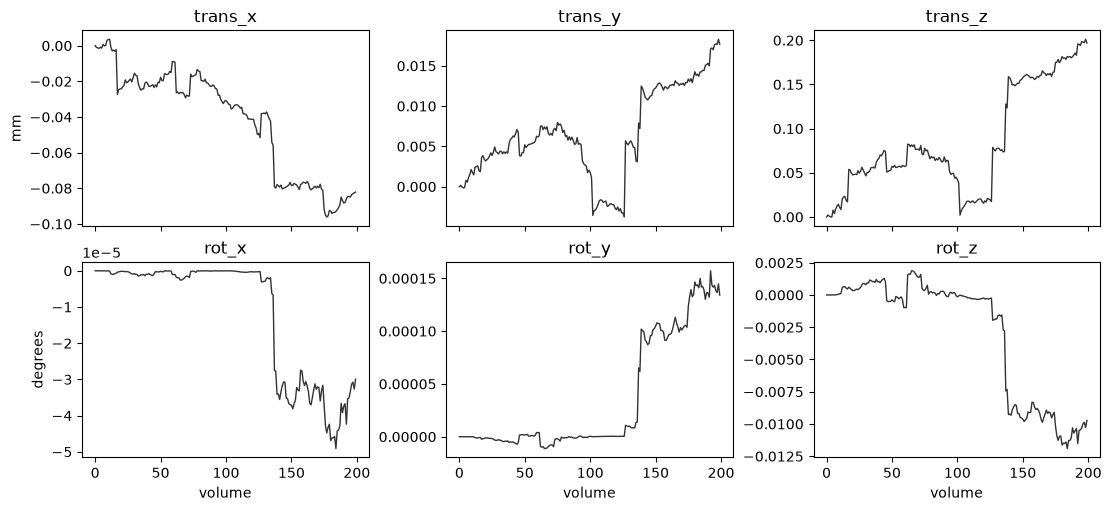

In [8]:
diff = shown['fsl'] - shown['afni']
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, layout='constrained')
for ax, col in zip(axes.flat, COLUMNS):
    ax.plot(diff[col], color='0.2', lw=1)
    ax.set_title(col)
axes[0, 0].set_ylabel('mm')
axes[1, 0].set_ylabel('degrees')
for ax in axes[1]:
    ax.set_xlabel('volume')
plt.show()

In [9]:
# Expectation 1: compare rotation differences with the largest product of two angles in a frame
angles = series_params['afni'][ROTATIONS].abs().to_numpy()
pair_products = np.sort(angles, axis=1)[:, 1:].prod(axis=1)
rot_diff = (series_params['fsl'][ROTATIONS] - series_params['afni'][ROTATIONS]).abs().to_numpy()
max_rot_diff = rot_diff.max()
max_product = pair_products.max()
max_trans_diff = diff[COLUMNS[:3]].abs().to_numpy().max()
e1_params = max_rot_diff <= max_product

display(
    Markdown(
        f'**Expectation 1, parameters: {verdict(e1_params, bold=False)}.** The rotations differ by at most '
        f'{np.rad2deg(max_rot_diff):.2g}°, against a largest product of two angles of '
        f'{np.rad2deg(max_product):.2g}° and a largest rotation of '
        f'{np.rad2deg(angles.max()):.2g}°. '
        'Its effect on FD is tested under Center distance. '
        f'The translations differ by up to {max_trans_diff:.2f} mm, because the rotation '
        'centers differ.'
    )
)

**Expectation 1, parameters: borne out.** The rotations differ by at most 0.012°, against a largest product of two angles of 0.018° and a largest rotation of 1.6°. Its effect on FD is tested under Center distance. The translations differ by up to 0.20 mm, because the rotation centers differ.

## FD and censoring

Do the two FD traces visibly differ?

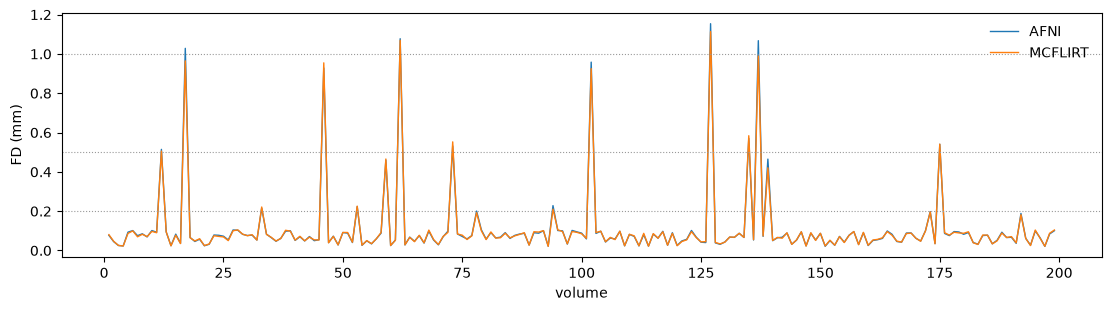

In [10]:
fig, ax = plt.subplots(figsize=(11, 3), layout='constrained')
for c in CONVENTIONS:
    ax.plot(series_fd[c], color=COLOR[c], lw=1, label=LABEL[c])
threshold_lines(ax)
ax.set(xlabel='volume', ylabel='FD (mm)')
ax.legend(frameon=False)
plt.show()

Which frames fall on different sides of a threshold?

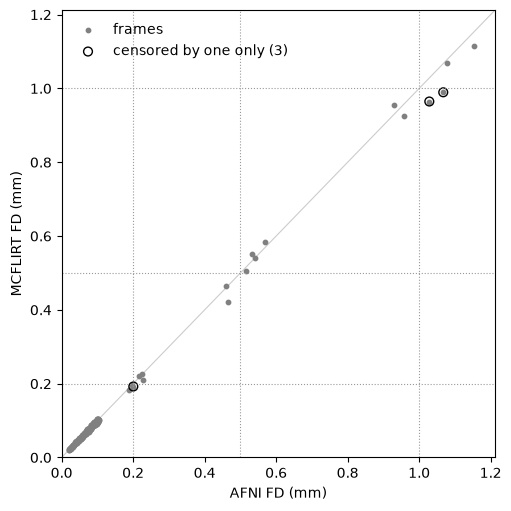

In [11]:
discordant = {
    tau: np.flatnonzero((series_fd['afni'] > tau) != (series_fd['fsl'] > tau))
    for tau in THRESHOLDS
}
flagged = np.unique(np.concatenate(list(discordant.values())))

fig, ax = plt.subplots(figsize=(5, 5), layout='constrained')
ax.scatter(series_fd['afni'], series_fd['fsl'], s=10, color='0.5', label='frames')
ax.scatter(
    series_fd['afni'][flagged],
    series_fd['fsl'][flagged],
    s=40,
    facecolor='none',
    edgecolor='k',
    label=f'censored by one only ({len(flagged)})',
)
lim = np.nanmax(list(series_fd.values())) * 1.05
ax.plot([0, lim], [0, lim], color='0.8', lw=0.8, zorder=0)
threshold_lines(ax, vertical=True)
ax.set(xlabel='AFNI FD (mm)', ylabel='MCFLIRT FD (mm)', xlim=(0, lim), ylim=(0, lim))
ax.legend(frameon=False, loc='upper left')
plt.show()

In [12]:
counts = pd.DataFrame(
    {tau: censor_counts(series_fd['afni'], series_fd['fsl'], tau) for tau in THRESHOLDS}
).T.rename(columns={'a_only': 'AFNI only', 'b_only': 'MCFLIRT only'})
counts['discordant frames'] = [', '.join(map(str, discordant[tau])) or '–' for tau in THRESHOLDS]
counts.rename_axis('τ (mm)')

,both,AFNI only,MCFLIRT only,neither,discordant frames
τ (mm),,,,,
0.2,15,1,0,183,78
0.5,10,0,0,189,–
1.0,2,2,0,195,"17, 137"


## Threshold error

The series has too few frames near each threshold for stable estimates.
They come instead from a sample of independent frame pairs drawn from the same motion model, dense near the thresholds.
Their transforms go through the same interfaces; 3dvolreg is not rerun.
`QUANTILE` sets the percentile the bounds use, and `BAND` the window of the band-averaged disagreement.

In [13]:
QUANTILE = 0.99
BAND = 0.1

rng = np.random.default_rng(1)
pairs = simulate_pairs(sample_fd_targets(10_000, rng), rng)
sample_xfms = volreg_to_ras(pairs, boldref)
sample_params, sample_fd_all = convert(sample_xfms, boldref, 'sample')
PAIRS = slice(1, None, 2)  # the frame-to-frame step within each pair
sample_fd = {c: fd[PAIRS] for c, fd in sample_fd_all.items()}
n_pairs = len(sample_fd['afni'])
sd = {'sample': pose_sd(sample_params['afni']), 'series': pose_sd(series_params['afni'])}

display(
    Markdown(
        f'{n_pairs:,} pairs. Their poses have SD {sd["sample"][0]:.2f} mm and '
        f"{sd['sample'][1]:.2f}°, against the series' {sd['series'][0]:.2f} mm and "
        f'{sd["series"][1]:.2f}°.'
    )
)

10,000 pairs. Their poses have SD 1.50 mm and 1.50°, against the series' 0.28 mm and 0.30°.

Does the relative FD difference depend on FD, and how does it compare with the `√3·d/50` worst case?

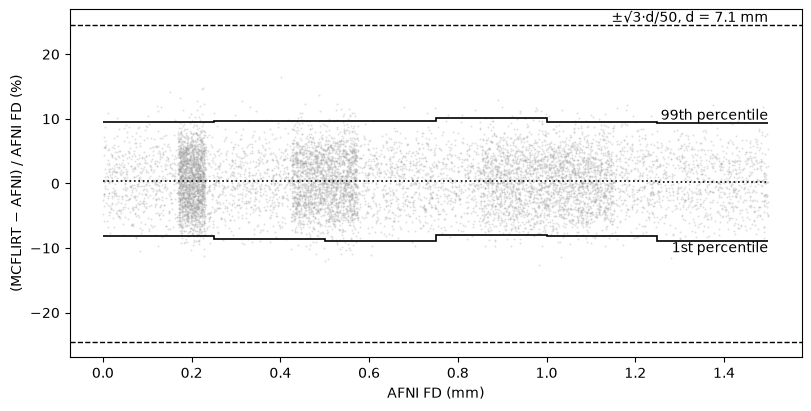

Per FD bin, the 99th percentile ranges +8.7% to +10.2%, the median -1.0% to +0.4%, and the 1st percentile -9.4% to -8.0%. No quantile moves by more than 1.5 percentage points across bins (criterion: 2): in this sample, the relative difference does not depend on FD, so bounds on it scale with τ.

In [14]:
FD_EDGES = np.arange(0, 1.75, 0.25)
Q = (1 - QUANTILE, 0.5, QUANTILE)
by_fd = pd.concat(
    {
        '(MCFLIRT − AFNI) / AFNI, by AFNI FD': relative_quantiles(
            sample_fd['afni'], sample_fd['fsl'], FD_EDGES, Q
        ),
        '(AFNI − MCFLIRT) / MCFLIRT, by MCFLIRT FD': relative_quantiles(
            sample_fd['fsl'], sample_fd['afni'], FD_EDGES, Q
        ),
    },
    axis=1,
)
analytic = np.sqrt(3) * d_ref / 50
rel = (sample_fd['fsl'] - sample_fd['afni']) / sample_fd['afni']

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
ax.scatter(sample_fd['afni'], 100 * rel, s=2, color='0.6', alpha=0.3, lw=0)
first = by_fd.columns.levels[0][0]
for q, ls in zip(Q, ('-', ':', '-')):
    ax.stairs(100 * by_fd[(first, q)], FD_EDGES, color='k', lw=1.2, ls=ls, baseline=None)
for sign in (1, -1):
    ax.axhline(sign * 100 * analytic, color='k', lw=1, ls='--')
ax.text(1.5, 100 * analytic, f'±√3·d/50, d = {d_ref:.1f} mm', va='bottom', ha='right')
ax.text(
    1.5, 100 * by_fd[(first, QUANTILE)].iloc[-1], percentile(QUANTILE), va='bottom', ha='right'
)
ax.text(1.5, 100 * by_fd[(first, Q[0])].iloc[-1], percentile(Q[0]), va='top', ha='right')
ax.set(xlabel='AFNI FD (mm)', ylabel='(MCFLIRT − AFNI) / AFNI FD (%)')
plt.show()

quantiles = by_fd.drop(columns='n', level=1)
spans = {q: quantiles.xs(q, axis=1, level=1) for q in Q}
span = max((s.max() - s.min()).max() for s in spans.values())
FLAT = 0.02  # largest spread of a quantile across FD bins, as a fraction of FD
flat = span < FLAT
display(
    Markdown(
        f'Per FD bin, the {percentile(QUANTILE)} ranges {spans[QUANTILE].min().min():+.1%} to '
        f'{spans[QUANTILE].max().max():+.1%}, the median {spans[0.5].min().min():+.1%} to '
        f'{spans[0.5].max().max():+.1%}, and the {percentile(Q[0])} '
        f'{spans[Q[0]].min().min():+.1%} to {spans[Q[0]].max().max():+.1%}. '
        + (
            f'No quantile moves by more than {100 * span:.1f} percentage points across bins '
            f'(criterion: {100 * FLAT:g}): '
            'in this sample, the relative difference does not depend on FD, so bounds on it '
            'scale with τ.'
            if flat
            else f'A quantile moves by {100 * span:.1f} percentage points across bins, more than the '
            f'{100 * FLAT:g}-point '
            'criterion: the relative difference depends on FD, so the τ-scaled bounds below are '
            'approximate.'
        )
    )
)
shown_q = by_fd.rename(columns=lambda q: q if q == 'n' else percentile(q), level=1)
shown_q.style.format('{:+.1%}', subset=shown_q.drop(columns='n', level=1).columns).format_index(
    lambda iv: f'{iv.left:g}–{iv.right:g} mm'
)

How far from τ can a frame measure under the other convention?

In [15]:
up, down = relative_spread(sample_fd['afni'], sample_fd['fsl'], QUANTILE)
up_max, down_max = relative_spread(sample_fd['afni'], sample_fd['fsl'], 1)


def headline(sign):
    """Markdown table of τ·(1 ± q) for the percentile, the sample maximum and the analytic bound."""
    cols = {
        f'{QUANTILE:.0%} of frames': up if sign > 0 else down,
        'sample maximum': up_max if sign > 0 else down_max,
        'analytic, translation term only': analytic,
    }
    rows = [
        '| τ (mm) | ' + ' | '.join(cols) + ' |',
        '| --- ' * (len(cols) + 1) + '|',
        *(
            f'| {tau:g} | '
            + ' | '.join(f'{tau * (1 + sign * q):.3f} ({sign * q:+.1%})' for q in cols.values())
            + ' |'
            for tau in THRESHOLDS
        ),
    ]
    return '\n'.join(rows)


headline_md = '\n'.join(
    [
        'A frame one convention keeps (FD ≤ τ) measures at most this under the other:',
        '',
        headline(1),
        '',
        'A frame one convention censors (FD > τ) measures at least this under the other:',
        '',
        headline(-1),
    ]
)
display(Markdown(headline_md))

A frame one convention keeps (FD ≤ τ) measures at most this under the other:

| τ (mm) | 99% of frames | sample maximum | analytic, translation term only |
| --- | --- | --- | --- |
| 0.2 | 0.219 (+9.7%) | 0.233 (+16.5%) | 0.249 (+24.5%) |
| 0.5 | 0.548 (+9.7%) | 0.583 (+16.5%) | 0.622 (+24.5%) |
| 1 | 1.097 (+9.7%) | 1.165 (+16.5%) | 1.245 (+24.5%) |

A frame one convention censors (FD > τ) measures at least this under the other:

| τ (mm) | 99% of frames | sample maximum | analytic, translation term only |
| --- | --- | --- | --- |
| 0.2 | 0.182 (-8.8%) | 0.172 (-14.2%) | 0.151 (-24.5%) |
| 0.5 | 0.456 (-8.8%) | 0.429 (-14.2%) | 0.378 (-24.5%) |
| 1 | 0.912 (-8.8%) | 0.858 (-14.2%) | 0.755 (-24.5%) |

The percentile is stable; is the maximum?
Each row averages 20 random subsamples of the pairs.

In [16]:
sub_rng = np.random.default_rng(2)
stability = {}
for n in (1_000, 2_500, 5_000, n_pairs):
    draws = [sub_rng.choice(n_pairs, n, replace=False) for _ in range(20)]
    stability[n] = np.mean(
        [
            [
                *relative_spread(sample_fd['afni'][i], sample_fd['fsl'][i], QUANTILE),
                *relative_spread(sample_fd['afni'][i], sample_fd['fsl'][i], 1),
            ]
            for i in draws
        ],
        axis=0,
    )
stability = pd.DataFrame.from_dict(
    stability,
    orient='index',
    columns=[f'up, {QUANTILE:.0%}', f'down, {QUANTILE:.0%}', 'up, max', 'down, max'],
).rename_axis('pairs')
growth = stability['up, max'].iloc[[0, -1]]
pct_moves = stability[f'up, {QUANTILE:.0%}']
display(
    Markdown(
        f'The maximum grows with sample size, from {growth.iloc[0]:+.1%} with '
        f'{growth.index[0]:,} pairs to {growth.iloc[1]:+.1%} with {growth.index[1]:,}; '
        f'the {percentile(QUANTILE)} stays between {pct_moves.min():+.2%} and '
        f'{pct_moves.max():+.2%}. The sample maximum is not a guarantee: a larger sample would '
        'raise it. The analytic bound covers only the translation term of FD.'
    )
)
stability.style.format('{:+.1%}').format_index('{:,}')

The maximum grows with sample size, from +13.7% with 1,000 pairs to +16.5% with 10,000; the 99th percentile stays between +9.66% and +9.68%. The sample maximum is not a guarantee: a larger sample would raise it. The analytic bound covers only the translation term of FD.

,"up, 99%","down, 99%","up, max","down, max"
pairs,,,,
"1,000",+9.7%,+8.8%,+13.7%,+12.0%
"2,500",+9.7%,+8.8%,+14.4%,+12.5%
"5,000",+9.7%,+8.8%,+15.4%,+13.4%
"10,000",+9.7%,+8.8%,+16.5%,+14.2%


Within this sample, the frames on the other side of τ, and the band-averaged disagreement:

In [17]:
sample_bounds = bounds_table(sample_fd, BAND)
(
    sample_bounds.style.format(precision=3)
    .format('{:d}', subset=sample_bounds.filter(like='n |').columns)
    .format_index('{:g}')
)

,max MCFLIRT | AFNI ≤ τ,min MCFLIRT | AFNI > τ,P(disagree) | AFNI near τ,n | AFNI near τ,max AFNI | MCFLIRT ≤ τ,min AFNI | MCFLIRT > τ,P(disagree) | MCFLIRT near τ,n | MCFLIRT near τ
τ (mm),,,,,,,,
0.2,0.221,0.184,0.173,1230,0.218,0.181,0.172,1232
0.5,0.554,0.447,0.179,1391,0.555,0.456,0.178,1397
1,1.106,0.914,0.165,1816,1.100,0.890,0.170,1775


How does the chance of disagreement fall with distance from τ?
The frames are binned by `|FD − τ| / τ`, in steps of 1%.

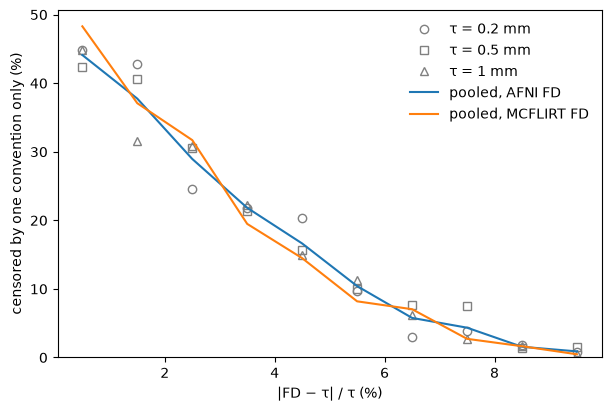

Pooled over thresholds (AFNI FD): 44% within 1%, 38% at 1%–2%, 25% at 2%–4%, 14% at 4%–6%, 5% at 6%–8%, 1% at 8%–10% of τ. The thresholds agree (chi-square test of homogeneity, p = 0.67), as expected when the relative difference does not depend on FD, so they are pooled. These rates come from a synthetic distribution of FD and motion directions. They show how disagreement falls off near τ; they are not rates for real data.

In [18]:
DIST_EDGES = np.linspace(0, BAND, 11)
curves = {
    c: disagreement_curve(sample_fd[c], sample_fd[o], THRESHOLDS, DIST_EDGES)
    for c, o in (('afni', 'fsl'), ('fsl', 'afni'))
}
per_tau = {
    tau: disagreement_curve(sample_fd['afni'], sample_fd['fsl'], (tau,), DIST_EDGES)
    for tau in THRESHOLDS
}

# Pool the thresholds only if their curves agree: chi-square test of homogeneity per bin
from scipy.stats import chi2, chi2_contingency

hits = {t: (c['p'].fillna(0) * c['n']).round().astype(int) for t, c in per_tau.items()}
stat = dof = 0
for iv in per_tau[THRESHOLDS[0]].index:
    table = np.array([[hits[t][iv], per_tau[t]['n'][iv] - hits[t][iv]] for t in THRESHOLDS])
    if (table.sum(axis=0) > 0).all():
        result = chi2_contingency(table)
        stat, dof = stat + result.statistic, dof + result.dof
homogeneous = chi2.sf(stat, dof)

mid = 100 * (DIST_EDGES[:-1] + DIST_EDGES[1:]) / 2
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for tau, marker in zip(THRESHOLDS, 'os^'):
    ax.plot(mid, 100 * per_tau[tau]['p'], marker, color='0.5', mfc='none', label=f'τ = {tau:g} mm')
for c in CONVENTIONS:
    ax.plot(mid, 100 * curves[c]['p'], color=COLOR[c], lw=1.5, label=f'pooled, {LABEL[c]} FD')
ax.set(
    xlabel='|FD − τ| / τ (%)',
    ylabel='censored by one convention only (%)',
    ylim=(0, None),
)
ax.legend(frameon=False)
plt.show()

key_edges = [0, 0.01, 0.02, 0.04, 0.06, 0.08, BAND]
key = disagreement_curve(sample_fd['afni'], sample_fd['fsl'], THRESHOLDS, key_edges)['p']
curve_md = ', '.join(
    f'{p:.0%} ' + ('within 1%' if iv.left == 0 else f'at {iv.left:.0%}–{iv.right:.0%}')
    for iv, p in key.items()
)
display(
    Markdown(
        f'Pooled over thresholds (AFNI FD): {curve_md} of τ. '
        + (
            f'The thresholds agree (chi-square test of homogeneity, p = {homogeneous:.2f}), '
            'as expected when the relative difference does not depend on FD, so they are pooled.'
            if homogeneous > 0.05
            else f'The thresholds differ (chi-square test of homogeneity, p = {homogeneous:.2g}); '
            'the pooled curve averages them.'
        )
        + ' These rates come from a synthetic distribution of FD and motion directions. They '
        'show how disagreement falls off near τ; they are not rates for real data.'
    )
)

Do the 3dvolreg series' FD pairs fall within the sample's bounds?

In [19]:
series_bounds = bounds_table(series_fd, BAND)
highs = sample_bounds.filter(like='max').columns
lows = sample_bounds.filter(like='min').columns
within = pd.concat(
    [series_bounds[highs] <= sample_bounds[highs], series_bounds[lows] >= sample_bounds[lows]],
    axis=1,
)
assert within.all(axis=None), within

# How close the series comes to each threshold, and how many disagreements the curve predicts
series_dist = {tau: np.abs(series_fd['afni'][1:] - tau) / tau for tau in THRESHOLDS}
n_near = sum(int((dist <= BAND).sum()) for dist in series_dist.values())
closest = min(dist.min() for dist in series_dist.values())
pooled = curves['afni']['p']
expected = sum(
    pooled.iloc[i]
    for dist in series_dist.values()
    for i in pooled.index.get_indexer(dist)
    if i >= 0
)
display(
    Markdown(
        f"All {within.size} series bounds lie within the sample's: the series is consistent "
        f'with the sample. That is a weak check: only {n_near} series frames lie within '
        f'±{BAND:.0%} of a threshold, and none closer than {closest:.1%}. For those frames, the '
        f'pooled curve predicts about {expected:.1f} disagreements; the series has {len(flagged)}.'
    )
)
pd.concat(
    {'series': series_bounds[[*highs, *lows]], 'sample': sample_bounds[[*highs, *lows]]}
).round(3)

All 12 series bounds lie within the sample's: the series is consistent with the sample. That is a weak check: only 14 series frames lie within ±10% of a threshold, and none closer than 0.3%. For those frames, the pooled curve predicts about 2.0 disagreements; the series has 3.

max MCFLIRT | AFNI ≤ τ  max AFNI | MCFLIRT ≤ τ  \
       τ (mm)                                                   
series 0.2                      0.196                   0.201   
       0.5                      0.465                   0.465   
       1.0                      0.955                   1.067   
sample 0.2                      0.221                   0.218   
       0.5                      0.554                   0.555   
       1.0                      1.106                   1.100   

               min MCFLIRT | AFNI > τ  min AFNI | MCFLIRT > τ  
       τ (mm)                                                  
series 0.2                      0.192                   0.215  
       0.5                      0.506                   0.514  
       1.0                      0.965                   1.077  
sample 0.2                      0.184                   0.181  
       0.5                      0.447                   0.456  
       1.0                      0.914                   0.890

## Regression

How much of each parameter set is left after regressing out the other?

In [20]:
series_regression = regression_summary(series_params)
series_regression.style.format('{:.6f}', subset=['min r2', 'max r2']).format(
    '{:.2g}', subset=['max rel. resid. SD']
)

In [21]:
series_resid = series_regression.groupby(level='parameters')['max rel. resid. SD'].max()
display(
    Markdown(
        f'On the reference grid, the residual SD is at most {series_resid["6"]:.2g} (6) and '
        f"{series_resid['24']:.2g} (24) of each column's SD. Expectation 3 is judged across "
        'center distances, under Center distance.'
    )
)

On the reference grid, the residual SD is at most 0.0024 (6) and 0.059 (24) of each column's SD. Expectation 3 is judged across center distances, under Center distance.

How large are the residuals next to the parameters? (MCFLIRT from AFNI, same y-axis per row.)

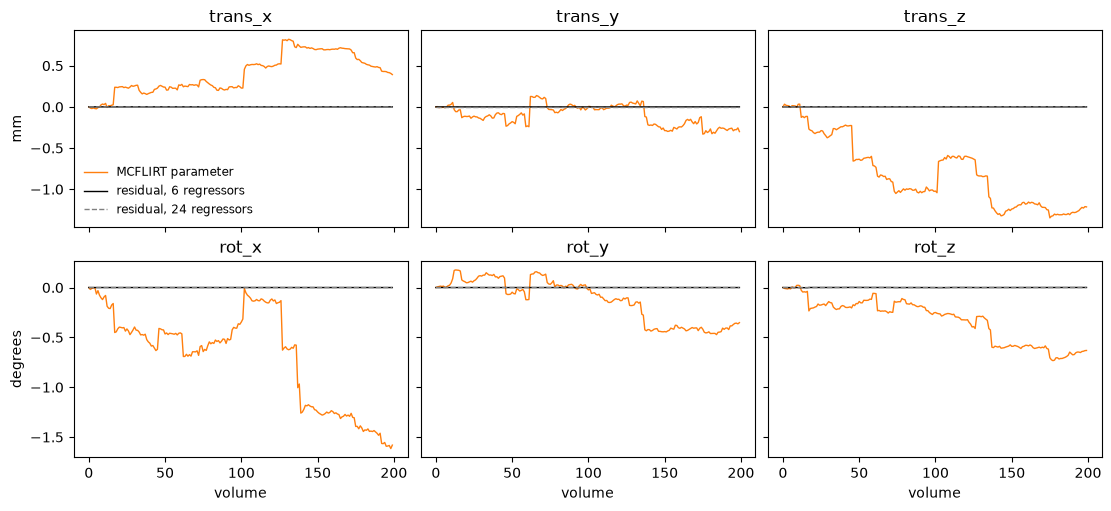

In [22]:
resid6, _ = regress_out(series_params['fsl'][COLUMNS], series_params['afni'][COLUMNS])
resid24, _ = regress_out(expand24(series_params['fsl']), expand24(series_params['afni']))
resid = {'6': to_display_units(resid6), '24': to_display_units(resid24[COLUMNS])}

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, sharey='row', layout='constrained')
for ax, col in zip(axes.flat, COLUMNS):
    ax.plot(shown['fsl'][col], color=COLOR['fsl'], lw=1, label='MCFLIRT parameter')
    ax.plot(resid['6'][col], color='k', lw=1, label='residual, 6 regressors')
    ax.plot(resid['24'][col], color='0.5', lw=1, ls='--', label='residual, 24 regressors')
    ax.set_title(col)
axes[0, 0].set_ylabel('mm')
axes[1, 0].set_ylabel('degrees')
axes[0, 0].legend(frameon=False, fontsize='small')
for ax in axes[1]:
    ax.set_xlabel('volume')
plt.show()

## Center distance

The center distance d runs from the grid center to the center of gravity. It depends on the field of view and on where the brain sits in it.
The series and sample transforms are re-expressed on padded copies of the reference (re-parameterized, not re-registered).
Padding with the image minimum moves the grid center, and with it AFNI's rotation center, but leaves the center of gravity in place.
Each row names where the padding goes.

In [23]:
PADS = [
    [(0, 0), (0, 0), (0, 0)],
    *([(p, 0), (0, 0), (0, 0)] for p in (5, 10, 20)),
    *([(0, 0), (p, 0), (0, 0)] for p in (5, 10, 20)),
    [(10, 0), (10, 0), (5, 0)],
]
SERIES = slice(1, None)  # every frame-to-frame step

sweep, series_sweep, sweep_bounds = {}, {}, {}
for i, pad in enumerate(PADS):
    name = pad_label(boldref, pad)
    if name == 'none':
        img, s_params, s_fd, x_params, x_fd = (
            boldref,
            sample_params,
            sample_fd_all,
            series_params,
            series_fd,
        )
    else:
        img = pad_image(boldref, pad)
        s_params, s_fd = convert(sample_xfms, img, f'pad{i}')
        x_params, x_fd = convert(series_xfms, img, f'series_pad{i}')
    d = center_distance(img)
    bound = {'d (mm)': d, '√3·d/50': np.sqrt(3) * d / 50}
    sample_reg, series_reg = regression_summary(s_params), regression_summary(x_params)
    sweep[name] = {
        **bound,
        **difference_stats(s_params, s_fd, PAIRS, QUANTILE),
        'resid. SD (6)': sample_reg.xs('6', level='parameters')['max rel. resid. SD'].max(),
        'resid. SD (24)': sample_reg.xs('24', level='parameters')['max rel. resid. SD'].max(),
    }
    reg24 = series_reg.xs('24', level='parameters')
    series_sweep[name] = {
        **bound,
        **difference_stats(x_params, x_fd, SERIES, QUANTILE),
        'min r2 (6)': series_reg.xs('6', level='parameters')['min r2'].min(),
        'min r2 (24)': reg24['min r2'].min(),
        'resid. SD (6)': series_reg.xs('6', level='parameters')['max rel. resid. SD'].max(),
        'resid. SD (24)': reg24['max rel. resid. SD'].max(),
        'worst 24 column': reg24.loc[reg24['max rel. resid. SD'].idxmax(), 'worst column'],
    }
    sweep_bounds[name] = bounds_table({c: f[PAIRS] for c, f in s_fd.items()}, BAND)

sweep = pd.DataFrame.from_dict(sweep, orient='index').sort_values('d (mm)')
series_sweep = pd.DataFrame.from_dict(series_sweep, orient='index').loc[sweep.index]
sweep_bounds = pd.concat(sweep_bounds, names=['padding'])
near, far, ref = sweep.iloc[0], sweep.iloc[-1], sweep.loc['none']
display(Markdown('The sample, per padding (relative FD differences, and regression):'))
sweep.rename_axis('padding').style.format(precision=3).format('{:.1f}', subset=['d (mm)'])

The sample, per padding (relative FD differences, and regression):

,d (mm),√3·d/50,max |rel. ΔFD|,translation term,rotation term,median,"up, pct","down, pct","up, max","down, max",resid. SD (6),resid. SD (24)
padding,,,,,,,,,,,,
20 mm posterior,3.3,0.113,0.116,0.071,0.059,0.013,0.049,0.046,0.116,0.104,0.026,0.076
none,7.1,0.245,0.165,0.124,0.053,0.031,0.097,0.088,0.165,0.142,0.026,0.175
20 mm right,11.6,0.400,0.230,0.223,0.053,0.038,0.134,0.118,0.240,0.194,0.026,0.274
40 mm posterior,13.1,0.453,0.244,0.223,0.058,0.055,0.165,0.142,0.258,0.205,0.026,0.289
40 mm right,20.4,0.707,0.320,0.312,0.052,0.058,0.211,0.174,0.398,0.285,0.026,0.447
"40 mm right, 40 mm posterior, 20 mm inferior",25.6,0.887,0.519,0.515,0.072,0.072,0.327,0.246,0.519,0.341,0.026,0.491
80 mm posterior,33.1,1.145,0.520,0.516,0.049,0.128,0.430,0.301,0.616,0.381,0.026,0.577
80 mm right,39.8,1.379,0.711,0.710,0.051,0.104,0.401,0.286,0.713,0.416,0.026,0.701


The series, per padding:

In [24]:
series_sweep.drop(columns=['up, pct', 'down, pct', 'up, max', 'down, max']).rename_axis(
    'padding'
).style.format(precision=3).format('{:.1f}', subset=['d (mm)']).format(
    '{:.4f}', subset=['min r2 (6)', 'min r2 (24)']
)

,d (mm),√3·d/50,max |rel. ΔFD|,translation term,rotation term,median,min r2 (6),min r2 (24),resid. SD (6),resid. SD (24),worst 24 column
padding,,,,,,,,,,,
20 mm posterior,3.3,0.113,0.053,0.052,0.014,0.012,1.0000,0.9993,0.002,0.027,trans_z_derivative1_power2
none,7.1,0.245,0.119,0.120,0.014,0.032,1.0000,0.9965,0.002,0.059,trans_x_derivative1_power2
20 mm right,11.6,0.400,0.152,0.159,0.015,0.042,1.0000,0.9908,0.002,0.096,trans_z_derivative1_power2
40 mm posterior,13.1,0.453,0.202,0.202,0.014,0.056,1.0000,0.9895,0.002,0.102,trans_z_derivative1_power2
40 mm right,20.4,0.707,0.267,0.258,0.015,0.059,1.0000,0.9797,0.002,0.142,trans_z_derivative1_power2
"40 mm right, 40 mm posterior, 20 mm inferior",25.6,0.887,0.363,0.359,0.015,0.061,1.0000,0.9696,0.002,0.174,trans_y_derivative1_power2
80 mm posterior,33.1,1.145,0.380,0.384,0.014,0.123,1.0000,0.9519,0.004,0.219,trans_z_derivative1_power2
80 mm right,39.8,1.379,0.495,0.484,0.012,0.094,1.0000,0.9468,0.002,0.231,trans_z_derivative1_power2


How do the bounds at each threshold move with center distance?

In [25]:
spread_bounds = pd.DataFrame(
    {
        (f'τ = {tau:g}', side): tau * (1 + sign * sweep[f'{side}, pct'])
        for tau in THRESHOLDS
        for side, sign in (('up', 1), ('down', -1))
    }
)
spread_bounds.insert(0, 'd (mm)', sweep['d (mm)'])
display(
    Markdown(
        f'FD under the other convention, for {QUANTILE:.0%} of frames kept (up) or censored '
        '(down) at τ, in mm:'
    )
)
spread_bounds.rename_axis('padding').style.format(precision=3).format('{:.1f}', subset=['d (mm)'])

/tmp/ipykernel_371788/2839547495.py:8: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  spread_bounds.insert(0, 'd (mm)', sweep['d (mm)'])


FD under the other convention, for 99% of frames kept (up) or censored (down) at τ, in mm:

The bounds and band-averaged disagreement per threshold, for each padding:

In [26]:
sweep_bounds.loc[sweep.index].drop(columns=sweep_bounds.filter(like='n |').columns).round(3)

max MCFLIRT | AFNI ≤ τ  \
padding                                      τ (mm)                           
20 mm posterior                              0.2                      0.208   
                                             0.5                      0.519   
                                             1.0                      1.052   
none                                         0.2                      0.221   
                                             0.5                      0.554   
                                             1.0                      1.106   
20 mm right                                  0.2                      0.227   
                                             0.5                      0.596   
                                             1.0                      1.124   
40 mm posterior                              0.2                      0.232   
                                             0.5                      0.568   
                                             1.0                      1.180   
40 mm right                                  0.2                      0.249   
                                             0.5                      0.597   
                                             1.0                      1.238   
40 mm right, 40 mm posterior, 20 mm inferior 0.2                      0.239   
                                             0.5                      0.682   
                                             1.0                      1.279   
80 mm posterior                              0.2                      0.264   
                                             0.5                      0.651   
                                             1.0                      1.361   
80 mm right                                  0.2                      0.262   
                                             0.5                      0.643   
                                             1.0                      1.556   

                                                     min MCFLIRT | AFNI > τ  \
padding                                      τ (mm)                           
20 mm posterior                              0.2                      0.190   
                                             0.5                      0.479   
                                             1.0                      0.967   
none                                         0.2                      0.184   
                                             0.5                      0.447   
                                             1.0                      0.914   
20 mm right                                  0.2                      0.175   
                                             0.5                      0.432   
                                             1.0                      0.887   
40 mm posterior                              0.2                      0.174   
                                             0.5                      0.429   
                                             1.0                      0.856   
40 mm right                                  0.2                      0.166   
                                             0.5                      0.406   
                                             1.0                      0.829   
40 mm right, 40 mm posterior, 20 mm inferior 0.2                      0.158   
                                             0.5                      0.385   
                                             1.0                      0.776   
80 mm posterior                              0.2                      0.146   
                                             0.5                      0.354   
                                             1.0                      0.690   
80 mm right                                  0.2                      0.147   
                                             0.5                      0.356   
                       

Does the relative FD difference grow with center distance as the analytic bound says?

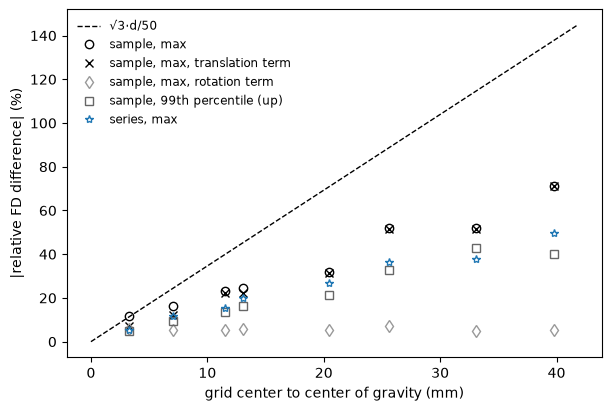

From d = 3.3 to 39.8 mm, the largest relative FD difference in the sample grows by 1.59% per mm (linear fit; the analytic worst case is 3.46% per mm).

**Expectation 2: borne out for the translation term**, which stays under √3·d/50 at every distance, in the series and the sample, at most 63% of it. Typical frames are smaller: the sample median is at most 13% of the bound. In the series (pose SD 0.30°), the total stays under the bound. In the sample (pose SD 1.50°), the total **exceeds the bound for the grid padded 20 mm posterior (d = 3.3 mm)**. The excess is the rotation term (Expectation 1).

In [27]:
slope = np.polyfit(sweep['d (mm)'], sweep['max |rel. ΔFD|'], 1)[0]
d_grid = np.linspace(0, sweep['d (mm)'].max() * 1.05, 2)

fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
ax.plot(d_grid, 100 * np.sqrt(3) * d_grid / 50, color='k', ls='--', lw=1, label='√3·d/50')
marks = [
    (sweep, 'max |rel. ΔFD|', 'o', 'k', 'sample, max'),
    (sweep, 'translation term', 'x', 'k', 'sample, max, translation term'),
    (sweep, 'rotation term', 'd', '0.6', 'sample, max, rotation term'),
    (sweep, 'up, pct', 's', '0.4', f'sample, {percentile(QUANTILE)} (up)'),
    (series_sweep, 'max |rel. ΔFD|', '*', COLOR['afni'], 'series, max'),
]
for table, column, marker, color, label in marks:
    ax.plot(table['d (mm)'], 100 * table[column], marker, color=color, mfc='none', label=label)
ax.set(xlabel='grid center to center of gravity (mm)', ylabel='|relative FD difference| (%)')
ax.legend(frameon=False, fontsize='small')
plt.show()


def over_bound(table, column):
    """Paddings, with distances, where ``column`` exceeds √3·d/50."""
    over = table[table[column] > table['√3·d/50']]
    return [f'the grid padded {name} (d = {d:.1f} mm)' for name, d in over['d (mm)'].items()]


over = {
    (label, column): over_bound(table, column)
    for label, table in (('sample', sweep), ('series', series_sweep))
    for column in ('max |rel. ΔFD|', 'translation term')
}
e2 = not (over[('sample', 'translation term')] or over[('series', 'translation term')])
over_total = over[('sample', 'max |rel. ΔFD|')] + over[('series', 'max |rel. ΔFD|')]
translation_share = max(
    (t['translation term'] / t['√3·d/50']).max() for t in (sweep, series_sweep)
)


def total_md(label, sd_rot):
    hits = over[(label, 'max |rel. ΔFD|')]
    where = ', '.join(hits)
    return f'In the {label} (pose SD {sd_rot:.2f}°), the total ' + (
        f'**exceeds the bound for {where}**.' if hits else 'stays under the bound.'
    )


display(
    Markdown(
        f'From d = {near["d (mm)"]:.1f} to {far["d (mm)"]:.1f} mm, the largest relative FD '
        f'difference in the sample grows by {100 * slope:.2f}% per mm (linear fit; the analytic '
        f'worst case is {100 * np.sqrt(3) / 50:.2f}% per mm).\n\n'
        f'**Expectation 2: {verdict(e2, bold=False)} for the translation term**, which '
        + (
            'stays under √3·d/50 at every distance, in the series and the sample, at most '
            f'{translation_share:.0%} of it. '
            if e2
            else 'exceeds √3·d/50 for '
            + ', '.join(
                over[('sample', 'translation term')] + over[('series', 'translation term')]
            )
            + '. '
        )
        + 'Typical frames are smaller: the sample median is at most '
        f'{(sweep["median"] / sweep["√3·d/50"]).max():.0%} of the bound. '
        + total_md('series', sd['series'][1])
        + ' '
        + total_md('sample', sd['sample'][1])
        + (' The excess is the rotation term (Expectation 1).' if over_total else '')
    )
)

Expectation 1 for FD: how much does the rotation term, which differs only through Euler order, change FD?
Padding doesn't change the rotations, so the rotation terms' difference is the same at every distance; only the AFNI FD it is divided by changes.

In [28]:
rot = {'series': series_sweep['rotation term'], 'sample': sweep['rotation term']}
e1_fd = max(r.max() for r in rot.values()) < NEGLIGIBLE_FD


def rotation_md(label):
    r = rot[label]
    return (
        f'up to {r["none"]:.1%} on the reference grid ({r.min():.1%}–{r.max():.1%} across '
        'paddings)'
    )


display(
    Markdown(
        f'**Expectation 1, FD: {verdict(e1_fd, bold=False)}** against the {NEGLIGIBLE_FD:.0%} '
        f'criterion. On the series (pose SD {sd["series"][1]:.2f}°), the rotation term changes '
        f'FD by {rotation_md("series")}. In the sample (pose SD {sd["sample"][1]:.2f}°), it '
        f'changes FD by {rotation_md("sample")}. It is larger with the larger poses and does not '
        'grow with center distance.'
    )
)

**Expectation 1, FD: not borne out** against the 1% criterion. On the series (pose SD 0.30°), the rotation term changes FD by up to 1.4% on the reference grid (1.2%–1.5% across paddings). In the sample (pose SD 1.50°), it changes FD by up to 5.3% on the reference grid (4.9%–7.2% across paddings). It is larger with the larger poses and does not grow with center distance.

How often do the conventions disagree near a threshold as center distance grows?

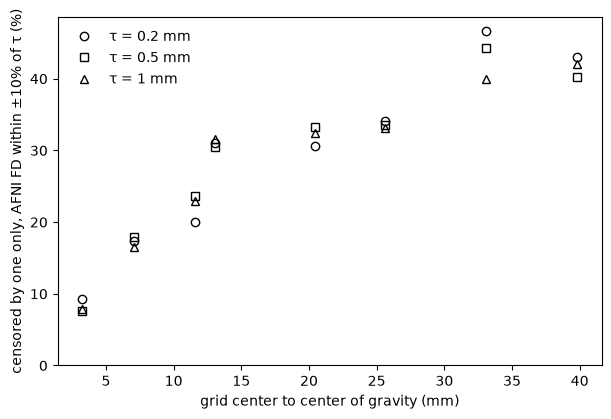

In [29]:
p_afni = sweep_bounds['P(disagree) | AFNI near τ'].unstack('τ (mm)').loc[sweep.index]
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for tau, marker in zip(THRESHOLDS, 'os^'):
    ax.plot(
        sweep['d (mm)'],
        100 * p_afni[tau],
        marker,
        color='k',
        mfc='none',
        label=f'τ = {tau:g} mm',
    )
ax.set(
    xlabel='grid center to center of gravity (mm)',
    ylabel=f'censored by one only, AFNI FD within ±{BAND:.0%} of τ (%)',
    ylim=(0, None),
)
ax.legend(frameon=False)
plt.show()

Does regression still remove one convention from the other as center distance grows?

In [30]:
e3_series = {m: (series_sweep[f'resid. SD ({m})'] < SMALL_RESIDUAL).all() for m in ('6', '24')}
e3_sample = {m: (sweep[f'resid. SD ({m})'] < SMALL_RESIDUAL).all() for m in ('6', '24')}
series_over24 = series_sweep[series_sweep['resid. SD (24)'] >= SMALL_RESIDUAL]
sample_over24 = sweep[sweep['resid. SD (24)'] >= SMALL_RESIDUAL]
series_ok24 = series_sweep[series_sweep['resid. SD (24)'] < SMALL_RESIDUAL]
worst = series_sweep.loc[series_sweep['resid. SD (24)'].idxmax()]


def model_md(table, model):
    return f"at most {table[f'resid. SD ({model})'].max():.2g} of the column's SD"


display(
    Markdown(
        f'**Expectation 3, series: {verdict(e3_series["6"], bold=False)} for 6 parameters, '
        f'{verdict(e3_series["24"], bold=False)} for 24.** With 6, the residual SD is '
        f'{model_md(series_sweep, "6")} at every distance. With 24, it is '
        + (
            f'{model_md(series_sweep, "24")}.'
            if e3_series['24']
            else (
                f'under the {SMALL_RESIDUAL:.0%} criterion up to d = '
                f'{series_ok24["d (mm)"].max():.1f} mm ({series_ok24["resid. SD (24)"].max():.2g}) '
                if not series_ok24.empty
                else ''
            )
            + f'and over it at {len(series_over24)} of {len(series_sweep)} distances, from '
            f'd = {series_over24["d (mm)"].min():.1f} mm, reaching '
            f'{worst["resid. SD (24)"]:.2f} (`{worst["worst 24 column"]}`) at '
            f'd = {worst["d (mm)"]:.1f} mm.'
        )
        + '\n\nThe sample is made of independent poses, not a time series, so its 24-parameter '
        'derivatives difference unrelated poses. With that caveat, its 6-parameter '
        f'residual SD is {model_md(sweep, "6")}, and the 24-parameter one '
        + (
            f'{model_md(sweep, "24")}.'
            if e3_sample['24']
            else f'reaches the criterion at {len(sample_over24)} of {len(sweep)} distances, '
            f'up to {sweep["resid. SD (24)"].max():.2f}.'
        )
    )
)

**Expectation 3, series: borne out for 6 parameters, not borne out for 24.** With 6, the residual SD is at most 0.0043 of the column's SD at every distance. With 24, it is under the 10% criterion up to d = 11.6 mm (0.096) and over it at 5 of 8 distances, from d = 13.1 mm, reaching 0.23 (`trans_z_derivative1_power2`) at d = 39.8 mm.

The sample is made of independent poses, not a time series, so its 24-parameter derivatives difference unrelated poses. With that caveat, its 6-parameter residual SD is at most 0.026 of the column's SD, and the 24-parameter one reaches the criterion at 7 of 8 distances, up to 0.70.

## Yardstick

RMS displacement of brain voxels between frames belongs to neither convention.
How closely does each FD follow it?

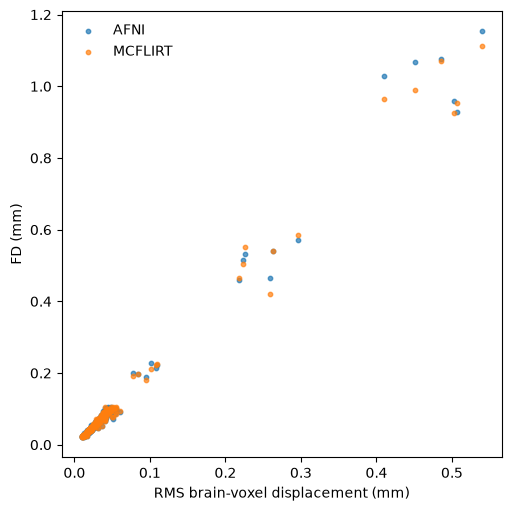

Correlation with RMS displacement: AFNI FD r = 0.992, MCFLIRT FD r = 0.994. The FD gap is at most 0.078 mm; RMS displacement ranges from 0.010 to 0.539 mm.

In [31]:
rms = rms_displacement(series_xfms, boldref)

fig, ax = plt.subplots(figsize=(5, 5), layout='constrained')
for c in CONVENTIONS:
    ax.scatter(rms, series_fd[c], s=10, color=COLOR[c], alpha=0.7, label=LABEL[c])
ax.set(xlabel='RMS brain-voxel displacement (mm)', ylabel='FD (mm)')
ax.legend(frameon=False)
plt.show()

r = {c: np.corrcoef(rms[1:], series_fd[c][1:])[0, 1] for c in CONVENTIONS}
gap = np.abs(series_fd['fsl'] - series_fd['afni'])[1:]
display(
    Markdown(
        f'Correlation with RMS displacement: AFNI FD r = {r["afni"]:.3f}, '
        f'MCFLIRT FD r = {r["fsl"]:.3f}. '
        f'The FD gap is at most {gap.max():.3f} mm; RMS displacement ranges from '
        f'{np.nanmin(rms):.3f} to {np.nanmax(rms):.3f} mm.'
    )
)

In [32]:
# Fill in the summary at the top
band_p = sweep_bounds.filter(like='P(disagree)')
distance_lines = [
    f'  - τ = {tau:g} mm: kept frames measure up to '
    f'{tau * (1 + near["up, pct"]):.3f} mm at d = {near["d (mm)"]:.1f} mm and '
    f'{tau * (1 + far["up, pct"]):.3f} mm at {far["d (mm)"]:.1f} mm; censored frames as low as '
    f'{tau * (1 - near["down, pct"]):.3f} and {tau * (1 - far["down, pct"]):.3f} mm.'
    for tau in THRESHOLDS
]
e3_24 = (
    f'borne out up to d = {series_ok24["d (mm)"].max():.1f} mm '
    f'({series_ok24["resid. SD (24)"].max():.2g}), **not borne out** from '
    f'd = {series_over24["d (mm)"].min():.1f} mm, reaching {worst["resid. SD (24)"]:.2f} at '
    f'd = {worst["d (mm)"]:.1f} mm'
    if not (series_ok24.empty or series_over24.empty)
    else f'{verdict(e3_series["24"])} (residual SD at most '
    f'{series_sweep["resid. SD (24)"].max():.2g})'
)

summary.update(
    Markdown(
        '\n'.join(
            [
                f'**Threshold bounds.** In this simulated sample ({n_pairs:,} frame pairs, pose SD '
                f'{sd["sample"][1]:.1f}°, on the reference grid, where the center distance is '
                f'd = {d_ref:.1f} mm), the relative FD difference between the conventions '
                + ('does not depend on FD' if flat else '**depends on FD**')
                + ', so the bounds scale with τ.',
                '',
                headline_md,
                '',
                f'- **The maximum is not a guarantee.** It grows with sample size (from '
                f'{growth.iloc[0]:+.1%} with {growth.index[0]:,} pairs to {growth.iloc[1]:+.1%} '
                f'with {growth.index[1]:,}); the {percentile(QUANTILE)} is stable '
                f'({pct_moves.min():+.2%} to {pct_moves.max():+.2%}). The analytic bound covers '
                "only FD's translation term.",
                f'- **Disagreement near τ** falls steeply with distance from it: {curve_md} of τ '
                f'(averaged over ±{BAND:.0%}: {pct_range(sample_bounds.filter(like="P(disagree)").stack())}). '
                'These rates come from a synthetic distribution of FD and motion directions, '
                'not from real data.',
                f'- **Center distance.** The bounds widen with d, which depends on the field of '
                'view and where the brain sits in it. From '
                f'd = {near["d (mm)"]:.1f} to {far["d (mm)"]:.1f} mm (sample, {percentile(QUANTILE)}):',
                *distance_lines,
                f'  - Band-averaged disagreement rises from {pct_range(band_p.loc[near.name].stack())} '
                f'to {pct_range(band_p.loc[far.name].stack())}.',
                f'- **3dvolreg series:** {len(flagged)} of {len(series_fd["afni"]) - 1} frames are '
                f'censored by one convention only, at any threshold. Only {n_near} frames lie within '
                f'±{BAND:.0%} of a threshold, none closer than {closest:.1%}; the disagreement curve '
                f'predicts about {expected:.1f} among them.',
                f'- **Expectation 1** (Euler order is negligible): {verdict(e1_params)} for the '
                f'parameters (at most {np.rad2deg(max_rot_diff):.2g}°); {verdict(e1_fd)} for FD. '
                f'The rotation term changes FD by up to {rot["series"].max():.1%} on the series (pose SD '
                f'{sd["series"][1]:.2f}°) and {rot["sample"].max():.1%} in the sample '
                f'({sd["sample"][1]:.2f}°), against the {NEGLIGIBLE_FD:.0%} criterion.',
                f'- **Expectation 2** (√3·d/50 bounds the change): {verdict(e2)} for the '
                'translation term'
                + (
                    ' at every distance'
                    if e2
                    else ', which exceeds it for '
                    + ', '.join(
                        over[('sample', 'translation term')] + over[('series', 'translation term')]
                    )
                )
                + '. The total '
                + (
                    'stays under it too.'
                    if not over_total
                    else f'exceeds it in the sample (pose SD {sd["sample"][1]:.1f}°) for '
                    + ', '.join(over[('sample', 'max |rel. ΔFD|')])
                    + ', because of Euler order'
                    + (
                        '; on the series it stays under.'
                        if not over[('series', 'max |rel. ΔFD|')]
                        else ', and on the series for '
                        + ', '.join(over[('series', 'max |rel. ΔFD|')])
                        + '.'
                    )
                ),
                f'- **Expectation 3** (regression leaves little), on the series: for 6 parameters, '
                f'{verdict(e3_series["6"])} (residual SD at most '
                f'{series_sweep["resid. SD (6)"].max():.2g} at every distance); for 24, {e3_24}.',
            ]
        )
    )
)